# 南京市植被覆盖状况遥感分析：Sentinel-2 NDVI

**平台：** Google Earth Engine
**数据集：** `COPERNICUS/S2_SR_HARMONIZED`  
**时间范围：** 2025-04-01 至 2025-10-01


## 0. 安装依赖


In [1]:
%pip install -q earthengine-api geemap matplotlib numpy

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. 导入 Python 库

In [1]:
import ee
import geemap
import matplotlib.pyplot as plt
from pathlib import Path

print('Python 环境准备完成！')

Python 环境准备完成！


## 2. 身份验证并连接 Google Earth Engine


In [18]:
PROJECT_ID = 'kjfx-512908'

ee.Authenticate()
ee.Initialize(project=PROJECT_ID)

print(ee.String('Hello, Google Earth Engine!').getInfo())

Hello, Google Earth Engine!


## 3. 定义研究区域：南京主城区示例范围

`ee.Geometry.Rectangle()` 的坐标顺序为：西边界经度、南边界纬度、东边界经度、北边界纬度。

In [7]:
roi = ee.Geometry.Rectangle([
    118.70, 31.98,
    118.90, 32.12
])

Map = geemap.Map(center=[32.05, 118.80], zoom=11)
Map.addLayer(roi, {'color': 'red'}, 'Study Area')
Map

Map(center=[32.05, 118.8], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

## 4. 获取 Sentinel-2 地表反射率影像

使用 Sentinel-2 Level-2A Harmonized 地表反射率数据。B4 为红光波段，B8 为近红外波段，二者空间分辨率均为 10 米。

In [8]:
START_DATE = '2025-04-01'
END_DATE = '2025-10-01'  # filterDate 的结束日期不包含在内

s2_collection = (
    ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
    .filterBounds(roi)
    .filterDate(START_DATE, END_DATE)
    .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40))
)

image_count = s2_collection.size().getInfo()
print('满足区域、日期和整景云量条件的影像数量：', image_count)

if image_count == 0:
    raise ValueError('没有检索到影像。请检查研究区、日期或云量筛选条件。')

满足区域、日期和整景云量条件的影像数量： 16


## 5. 云掩膜并生成中值合成影像

使用 Sentinel-2 的 `SCL`（场景分类）波段屏蔽无数据、饱和/缺陷像元、云影、未分类像元、中高概率云、卷云和积雪。然后选取 B2、B3、B4、B8，并将整数存储值乘以 0.0001 转换为地表反射率。

In [9]:
def mask_s2_clouds(image):
    scl = image.select('SCL')

    mask = (
        scl.neq(0)
        .And(scl.neq(1))
        .And(scl.neq(3))
        .And(scl.neq(7))
        .And(scl.neq(8))
        .And(scl.neq(9))
        .And(scl.neq(10))
        .And(scl.neq(11))
    )

    return (
        image.updateMask(mask)
        .select(['B2', 'B3', 'B4', 'B8'])
        .multiply(0.0001)
        .copyProperties(image, ['system:time_start'])
    )


s2_clean = s2_collection.map(mask_s2_clouds)
print('完成云掩膜处理的影像数量：', s2_clean.size().getInfo())

composite = s2_clean.median().clip(roi)
print('中值合成影像已生成。')

完成云掩膜处理的影像数量： 16
中值合成影像已生成。


## 6. 计算 NDVI 并统计区域平均值

公式：`NDVI = (NIR - Red) / (NIR + Red)`。对于 Sentinel-2，NIR 对应 B8，Red 对应 B4。

In [10]:
ndvi = (
    composite
    .normalizedDifference(['B8', 'B4'])
    .rename('NDVI')
)

ndvi_stats = ndvi.reduceRegion(
    reducer=ee.Reducer.mean(),
    geometry=roi,
    scale=10,
    maxPixels=1e13,
    tileScale=4
)

mean_ndvi = ndvi_stats.get('NDVI').getInfo()
print('研究区平均 NDVI：', mean_ndvi)

研究区平均 NDVI： 0.39700380700484944


## 7. 可视化真彩色影像和 NDVI 专题图

真彩色影像使用 B4、B3、B2；NDVI 图层使用棕色—浅色—绿色渐变。可以在地图图层控制器中切换显示。

In [11]:
rgb_vis = {
    'bands': ['B4', 'B3', 'B2'],
    'min': 0.02,
    'max': 0.30
}

ndvi_vis = {
    'min': -0.2,
    'max': 0.8,
    'palette': ['8c510a', 'f6e8c3', 'c7eae5', '01665e']
}

ndvi_map = geemap.Map(center=[32.05, 118.80], zoom=11)
ndvi_map.addLayer(composite, rgb_vis, 'Sentinel-2 True Color')
ndvi_map.addLayer(ndvi, ndvi_vis, 'NDVI 2025')
ndvi_map.addLayer(roi, {'color': 'red'}, 'Study Area')
ndvi_map

Map(center=[32.05, 118.8], controls=(WidgetControl(options=['position', 'transparent_bg'], position='topright'…

## 8. 绘制 NDVI 直方图和优化后的专题图

从研究区随机抽取最多 5,000 个有效像元，绘制 NDVI 值分布。抽样直方图用于辅助描述，不等同于对全部像元逐个统计。

有效抽样像元数量： 5000


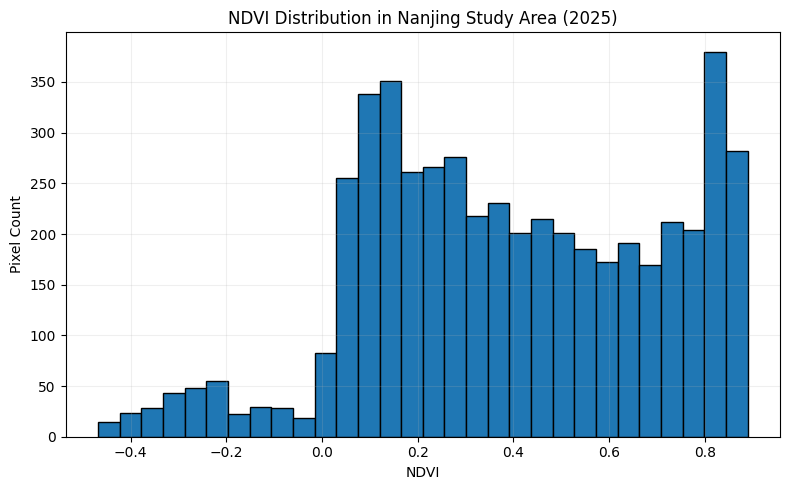

In [12]:
samples = ndvi.sample(
    region=roi,
    scale=10,
    numPixels=5000,
    seed=42,
    geometries=False
)

ndvi_values = samples.aggregate_array('NDVI').getInfo()
print('有效抽样像元数量：', len(ndvi_values))

plt.figure(figsize=(8, 5))
plt.hist(ndvi_values, bins=30, edgecolor='black')
plt.xlabel('NDVI')
plt.ylabel('Pixel Count')
plt.title('NDVI Distribution in Nanjing Study Area (2025)')
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

In [13]:
# 统计 NDVI 的最小值和最大值
ndvi_stats = ndvi.reduceRegion(
    reducer=ee.Reducer.minMax(),
    geometry=roi,
    scale=10,
    maxPixels=1e9,
    bestEffort=True
)

print("NDVI 最小值和最大值：")
print(ndvi_stats.getInfo())

NDVI 最小值和最大值：
{'NDVI_max': 0.9078490391294279, 'NDVI_min': -0.6452830188679246}


In [14]:
# 计算 NDVI 的第 2、98 百分位数
percentile_stats = ndvi.reduceRegion(
    reducer=ee.Reducer.percentile([2, 98]),
    geometry=roi,
    scale=10,
    maxPixels=1e9,
    bestEffort=True,
    tileScale=4
)

percentile_result = percentile_stats.getInfo()

print("NDVI 百分位数统计：")
print(percentile_result)

NDVI 百分位数统计：
{'NDVI_p2': -0.2850751163221742, 'NDVI_p98': 0.8630908342447893}


In [15]:
# 获取百分位数
vmin = percentile_result['NDVI_p2']
vmax = percentile_result['NDVI_p98']

# 设置 NDVI 可视化参数
ndvi_vis = {
    'min': vmin,
    'max': vmax,
    'palette': [
        '#8c510a',
        '#d8b365',
        '#f6e8c3',
        '#c7eae5',
        '#5ab4ac',
        '#01665e'
    ]
}

# 添加优化后的 NDVI 图层
Map.addLayer(
    ndvi,
    ndvi_vis,
    'Nanjing NDVI'
)

Map

Map(bottom=425961.0, center=[32.04620586520412, 118.89490127563478], controls=(WidgetControl(options=['positio…

## 9. 将影像导出到 Google Drive


In [16]:
source_bands = (
    composite
    .select(['B4', 'B8'])
    .multiply(10000)
    .round()
    .toUint16()
)

source_task = ee.batch.Export.image.toDrive(
    image=source_bands,
    description='Nanjing_Sentinel2_B4_B8_2025',
    folder='GEE_Homework',
    fileNamePrefix='Nanjing_Sentinel2_B4_B8_2025',
    region=roi,
    scale=10,
    maxPixels=1e13,
    fileFormat='GeoTIFF'
)

ndvi_task = ee.batch.Export.image.toDrive(
    image=ndvi.toFloat(),
    description='Nanjing_NDVI_2025',
    folder='GEE_Homework',
    fileNamePrefix='Nanjing_NDVI_2025',
    region=roi,
    scale=10,
    maxPixels=1e13,
    fileFormat='GeoTIFF'
)

source_task.start()
ndvi_task.start()

print('两个导出任务已提交。')
print('Source task:', source_task.status())
print('NDVI task:', ndvi_task.status())

两个导出任务已提交。
Source task: {'state': 'READY', 'description': 'Nanjing_Sentinel2_B4_B8_2025', 'priority': 100, 'creation_timestamp_ms': 1793615134447, 'update_timestamp_ms': 1793615134447, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': '5VS4NAHFKYAFVKDBY6YCB5SD', 'name': 'projects/kjfx-512908/operations/5VS4NAHFKYAFVKDBY6YCB5SD'}
NDVI task: {'state': 'READY', 'description': 'Nanjing_NDVI_2025', 'priority': 100, 'creation_timestamp_ms': 1793615136160, 'update_timestamp_ms': 1793615136160, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': '23LSTU3D3VHQ3WY74KNHC5OF', 'name': 'projects/kjfx-512908/operations/23LSTU3D3VHQ3WY74KNHC5OF'}


## 10. 检查导出任务状态


In [17]:
print('Source task status:')
print(source_task.status())

print('\nNDVI task status:')
print(ndvi_task.status())

Source task status:
{'state': 'RUNNING', 'description': 'Nanjing_Sentinel2_B4_B8_2025', 'priority': 100, 'creation_timestamp_ms': 1793615134447, 'update_timestamp_ms': 1793615138574, 'start_timestamp_ms': 1793615138467, 'task_type': 'EXPORT_IMAGE', 'attempt': 1, 'id': '5VS4NAHFKYAFVKDBY6YCB5SD', 'name': 'projects/kjfx-512908/operations/5VS4NAHFKYAFVKDBY6YCB5SD'}

NDVI task status:
{'state': 'READY', 'description': 'Nanjing_NDVI_2025', 'priority': 100, 'creation_timestamp_ms': 1793615136160, 'update_timestamp_ms': 1793615141567, 'start_timestamp_ms': 0, 'task_type': 'EXPORT_IMAGE', 'id': '23LSTU3D3VHQ3WY74KNHC5OF', 'name': 'projects/kjfx-512908/operations/23LSTU3D3VHQ3WY74KNHC5OF'}
